<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/geometry_of_SVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Geometry of SVD

Today we start with an overview, and some intuitions and a simple usage.

> We will go in depth into SVD next time.

The singular value decomposition (SVD) of a matrix $M$ gives us three matrices:

> No they are not $S$, $V$, and $D$.

- $U$ (orthonormal)
- $\Sigma$   (diagonal, we call it S in code)
- $V^T$ (orthonormal , we call it Vt in code)

Their product $U{\Sigma}V^T = M$.

## More info in the handwritten notes (see links).




# SVD is overpowered

* tells us what any linear transformation can do
* lets us find convenient orthonormal bases (super useful for linear dimensionality reduction)

> So we will often perform a change of basis to this new basis given by SVD!

* the foundation of many applied tools (PCA, least squares, low-rank approximation)
> We'll use it for image compression and dimensionality reduction

* will finally give us vectors aligned with the axis of the ellipse!
* well, it works in any dimension

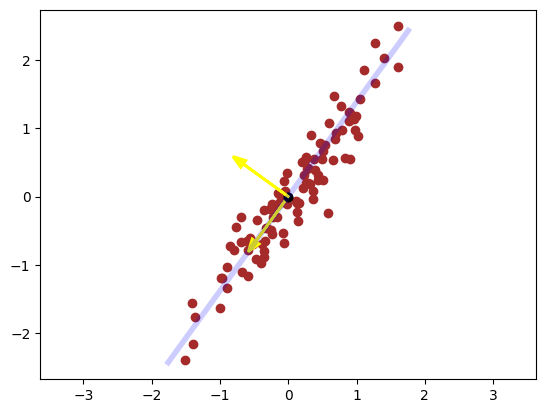

# Let's see if this works!

In [ ]:
#@title
from ipywidgets import *
import ipywidgets as widgets

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as lines

In [ ]:
M = [[1,2],[3,4]]

M = [[1,0],[2,1]]
U,S,Vt = np.linalg.svd(M) # that's how you compute it -- read the documentation though

# Note that S is a vector of the diagonal elements of the matrix

S = np.diag(S) # now we have a matrix we can multiply

# Task 1: Play with the visualization below, try e.g. the sheer matrix

The step goes from 0 to 3 and shows you the different phases into which SVD decomposes a linear transformation (by decomposing the matrix of this linear transformation).

* What happens for the shear transformation matrix?

* Check also matrices of rank < 2 (e.g. [[1,0],[1,0]]).

* Check matrices that flip one or 2 coordinates. What's their determinant?

* Anything else you're curious about?





# Impl.

In [ ]:
#@title just defining the points to transform
A = np.array([(np.sin(x), np.cos(x))
  for x in np.linspace(0,np.pi*2, 100, endpoint = False)])

c = [1,1]

P = A
# P = np.vstack((A,A*2))

In [ ]:
#@title
def prod(t, U, Sm, Vt):
  '''
  t is an integer between 0 and 3, and decides how many
  'steps' of SVD are done. So 1 is just the initial rotation/reflection
  '''
  if t == 1:
    return Vt
  if t == 2:
    return Sm @ Vt
  if t == 3:
    return U @ Sm @ Vt

  return np.eye(2)

def animate(M):
  U, S, Vt = np.linalg.svd(M)
  Sm = np.diag(S)
  return lambda t: prod(t, U, Sm, Vt)

In [ ]:
#@title implementation (read at your own risk)
import matplotlib.pyplot as plt
import matplotlib.lines as lines
import matplotlib.patches as pt

sl = lambda x : widgets.FloatSlider(value=x, min = -5., max = 5., step = 0.1)

R = np.vstack(([0,0], [0,1], [1,1], [1,0], [0,0]))

def plot_grid(A, **kw):
  k = 13
  q = 1e6
  S = np.array([(-q, x) for x in np.arange(-k,k,1)])
  E = S + np.array((2*q, 0))
  S = (A @ S.T).T
  E = (A @ E.T).T
  [plt.gca().add_artist(lines.Line2D([a[0],b[0]], [a[1], b[1]], alpha = kw['alpha'], color = kw['color'])) for a,b in zip(S,E)]

def plot_basis(A, **kw):
  S = np.zeros((2,2))
  E = np.eye(2)
  S = (A @ S.T).T
  E = (A @ E.T).T
  [plt.gca().add_artist(lines.Line2D([a[0],b[0]], [a[1], b[1]], alpha = kw['alpha'], color = kw['color'], lw = 3)) for a,b in zip(S,E)]


def get_axes(M):
  U,S,Vt = np.linalg.svd(M)
  return U@np.diag(S)


def print_matrix_and_decomp(A):
  print("matrix A:\n", A)
  for name, mat in zip("U S V^T".split(), np.linalg.svd(A)):
    print(f"{name}:\n{mat}")


def vis_transform(A,
                  grid = True, connect = True, simple = False,
                  basis = True, basis_image = True, eigenv = True,
                  ellipse_axes = True,
                  larger_boxes = False,
                  dx = 0, dy = 0, many = False, T = 0):
  plt.figure(figsize = (14, 14))

 # def print(*k): pass

  A_orig = A.copy()
  # print_matrix_and_decomp(A)
  C = P + (dx, dy)

  if not simple:
    plt.gca().add_patch( pt.Polygon((A@R.T).T, color = 'red', alpha = 0.1) )

  Q = [(1,(0,0)), (1, (0,0)), (1, (2,0)), (1, (0,2)), (1, (2,2))] if many else [(1,(0,0))]
  for a,t in Q:
    C1 = (a*C + t)
    C2 = (A@C1.T).T

    if not simple:
      plt.scatter(C2[:,0], C2[:,1], alpha = 0.3, color = 'red')
    plt.scatter(1.2*C2[:,0], 1.2*C2[:,1], alpha = 0.0, color = 'red')

  A = animate(A)(T)

  CURRENT_COLOR = 'green'

  print(f"matrix A_{T} \n", A)

  old_alpha = 0.05
  new_alpha = 0.5

  if connect:
    for a,t in [(1,(0,0))]:
      C1 = (a*C + t)
      C2 = (A@C1.T).T

      for p,q in zip(C1, C2):
        plt.gca().plot([p[0], q[0]], [p[1], q[1]], alpha = 0.3, color='blue')

  if basis:
    plot_basis(np.eye(2), alpha=0.5, color='blue')

  if basis_image:
    plot_basis(A, alpha=1, color='red')

  if grid:
    plot_grid(np.eye(2), alpha=old_alpha, color='blue')
    plot_grid([[0,-1],[1,0]], alpha=old_alpha, color='blue')
    plot_grid(A, alpha=new_alpha, color='red')
    plot_grid(A@[[0,-1],[1,0]], alpha=new_alpha, color='yellow')

  if larger_boxes:
    plt.gca().add_patch( pt.Polygon(3*R, color='blue', alpha=old_alpha) )
    plt.gca().add_patch( pt.Polygon((3*A@R.T).T, color='red', alpha=new_alpha/2) )

  if not simple:
    #plt.gca().add_patch( pt.Polygon(R, color = 'blue', alpha = old_alpha*4) )
    plt.gca().add_patch( pt.Polygon((A@R.T).T, color=CURRENT_COLOR, alpha=new_alpha/2) )

  Q = [(1,(0,0)), (1, (0,0)), (1, (2,0)), (1, (0,2)), (1, (2,2))] if many else [(1,(0,0))]
  for a,t in Q:
    C1 = (a*C + t)
    C2 = (A@C1.T).T

    #plt.scatter(C1[:,0], C1[:,1], alpha = 0.3, color = 'blue')
    plt.scatter(C2[:,0], C2[:,1], alpha=1, color='green')


  p = np.random.randn(2)
  p /= np.linalg.norm(p)
  ps = [p]

  #plt.plot(*p, '-o', markersize = 20)

  ps = np.array(ps)
  #plt.plot(*ps.T, '-o', markersize = 5)

  U, S, Vt = np.linalg.svd(A)
  X = get_axes(A)

  colors = ['yellow', 'yellow', 'orange', 'orange']

  if X is not None and ellipse_axes:
    plot_basis(X, alpha=0.9, color=colors[T])
    #plot_basis(-X, alpha = 0.9, color = 'red')

  d = np.linalg.det(A_orig)
  r = np.linalg.matrix_rank(A_orig)
  dc = np.linalg.det(A)
  rc = np.linalg.matrix_rank(A)
  #d2 = get_abs_determinant(A_orig)
  #r2 = get_rank(A_orig)
  #plt.title(f'''det(A) = {d:3f}, rank(A) = {r}\n
  #              det(A_{T}) = {dc:3f}, rank(A_{T}) = {rc}\n''')

  if eigenv:
    S, E = np.linalg.eig(A)

    plot_basis(E*S, alpha = 0.7, color = 'g', linewidth=10)
    plot_basis(-E*S, alpha = 0.7, color = 'g', linewidth=10)

  plt.axis('equal')
  plt.show()

In [ ]:
#@title
def go(ellipse_axes, connect, eig, a,b,c,d, step):
  A = np.array([[a,c],[b,d]])
  print(A)
  vis_transform(A, grid=False, connect=connect, basis=False, basis_image=False,
                ellipse_axes=ellipse_axes,
                larger_boxes=False, dx=0, dy=0, many=False, simple=False,
                  T=step, eigenv=eig)

# How it works

> The faded red stuff is the image of the the linear transformation you chose.

You can play with paramater $t$, which controls how many matrices coming from the SVD decomposition of matrix $A$ are multiplied:
- 0 gives the identity (let's call it $A_0$)
- 1 gives $V^T$ ($A_1$)
- 2 gives $SV^T$ ($A_2$)
- 3 is $USV^T$ (which is just $A_3 = A$)

> In other words it shows the phases in which every linear transformation can be performed

In [ ]:
interactive_plot = interactive(go,
                               ellipse_axes = True,
                               connect = False,
                               eig = False,
                               a = sl(-1), b = sl(2),
                               c = sl(3), d = sl(0.5),
                               step = widgets.IntSlider(value=3, min=0,
                                                       max=3, step=1))

interactive_plot.layout.height = '1300px'
interactive_plot.layout.width = '800px'
HBox([interactive_plot])

# (Example) Simple application: Finding a convenient orthonormal basis, or where is the river?

Suppose the dots are locations around the river we discussed last. Say you only see the points -- you should be able to guess there the river is.

Or: how to find another, more convenient orthonormal basis?

Trick: we consider our $n$ data points in 2D as a linear transformation $\mathbb{R}^n \to \mathbb{R^2}$. And check **which resulting vector has undergone the biggest stretch**.

> The one winner is our river as we discussed in class!

Importantly, we can do this in any dimension. Note that we'd get $m$ vectors in $\mathbb{R^m}$, some of which we'd keep.

In [ ]:
X = (np.random.randn(100, 2) * (0.2, 1))@[[0.7, -0.5],[0.7, 1]]

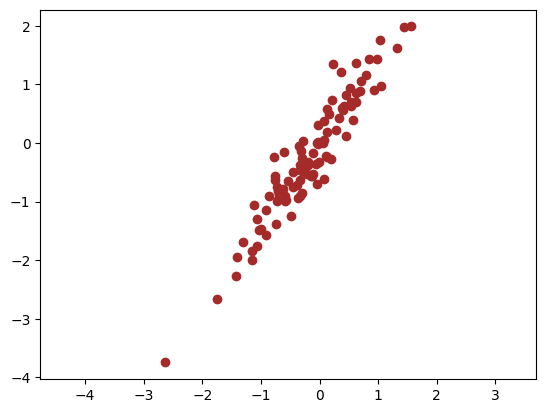

In [ ]:
plt.scatter(*X.T, c='brown');
plt.axis('equal');

## Let's have a first look at non-square matrices

In [ ]:
# Just a convenient function to play with matrices of arbitrary size
from scipy.linalg import diagsvd

M = X.T # !
U, S, Vt = np.linalg.svd(M, full_matrices=True)

S = diagsvd(S, *M.shape) # nicely pads the matrix with zeros
print('shapes:', M.shape, U.shape, S.shape, Vt.shape)

shapes: (2, 100) (2, 2) (2, 100) (100, 100)


In [ ]:
assert np.allclose(U@S@Vt, M) # M = USV^T, so it actually works!

In [ ]:
# @title draw_arrow
def draw_arrow(v, t, txt = "", color = 'g', bold = False):
  '''I plot a nice arrow between v,t. No need to look inside, just try me out.'''
  v = np.asarray(v)
  t = np.asarray(t)
  dxy = t-v
  plt.scatter(*v, c = 'k')
  plt.scatter(*(v+dxy), c = 'k', alpha=0)
  head_width = np.linalg.norm(dxy)/20. * [1,2.5][bold]
  line_width = 1 if not bold else 2
  plt.arrow(*v, *dxy, length_includes_head=True,
            head_width=head_width, linewidth=line_width, color=color)
  if txt:
    plt.text(*(v+dxy/2. + (0.01, 0)), txt, c = 'gray', fontsize = 20)
  plt.axis('equal') # otherwise it looks ugly

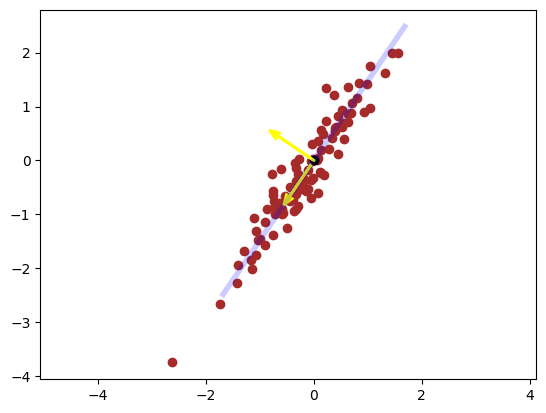

In [ ]:
plt.scatter(*X.T, c = 'brown')
v = U.T[0]
c = 3; plt.plot([-c*v[0], +c*v[0]], [-c*v[1], +c*v[1]], c='blue', alpha=0.2, lw=4)

for basis_vector in U.T:
  draw_arrow((0,0), basis_vector, bold=True, color='yellow')

plt.axis('equal');

# What else can we do?

We could be efficient and use a single coordinate for each point.

This loses some information -- it projects onto the (span of) this basis vector

> So it's like pointing someone to a point on the river and hoping he'll find the nearby spot (that they can see from there) by going perpendicularly from there.



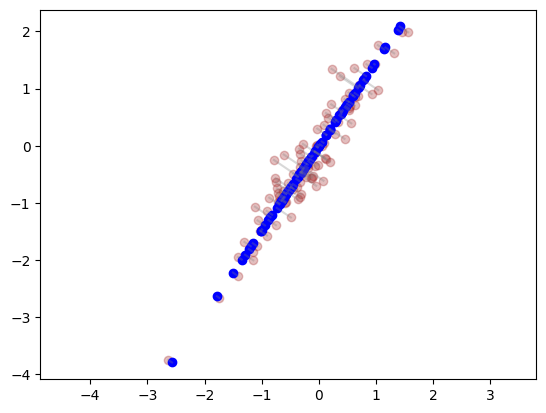

In [ ]:
v = U.T[0] # take one vector which will be our truncated-basis
new_1d_coordinates = X@v # projection lengths onto the span of truncated-basis

# We got the coordinates, but we need the points, so
# we'll just rescale v depending on how far along the river it is
Xp = new_1d_coordinates.reshape(-1, 1) @ v.reshape(1,-1)
# trick: Xp = np.outer(new_1d_coordinates, v)

plt.scatter(*X.T, alpha = 0.3, c='brown')
plt.scatter(*Xp.T, c = 'blue')

for p,q in zip(X, Xp):
  plt.plot([p[0], q[0]], [p[1], q[1]], '-', c = 'gray', alpha = 0.3)

plt.axis('equal');

# Task 2 Try to implement and test the below -- using only SVD + python (no other numpy functions)

> You can assume it's a 2x2 matrix for simplicity. It's mostly about the concepts here.

In [ ]:
#@title
# 'Hint': **without** using np.linalg.det
def get_abs_determinant(M):
  U,S,Vt = np.linalg.svd(M)
  return 0

# 'Hint': **without** using np.linalg.matrix_rank
def get_rank(M):
  U,S,Vt = np.linalg.svd(M)
  return 0

In [ ]:
Q = np.array([[1,1], [2,2]])
get_abs_determinant(Q), get_rank(Q)

(0, 0)

In [ ]:
# verify using numpy functions...